# PH 4050  Computational Electrodynamics

Pamudu Amarasinghe

 2D geometry (Cross-section) of a coaxial transmission line. It consists of an inner conductor of rectangular cross-section a × b, placed coaxially within an outer conductor of rectangular cross-section c × d with a = b = 1 cm and c = d = 2 cm. As boundary conditions, choose the potential Φ on the inner conductor Φ1 = 1 V and the outer conductor Φ2 = 0 V. Follow the given steps to compute the capacitance per unit length C of the given transmission line.  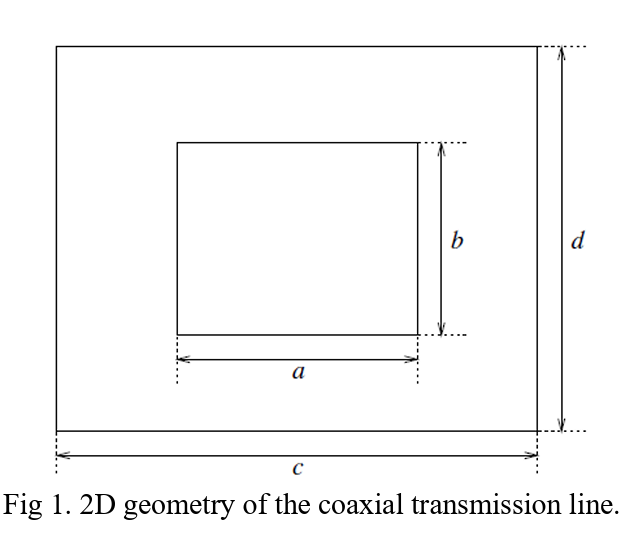

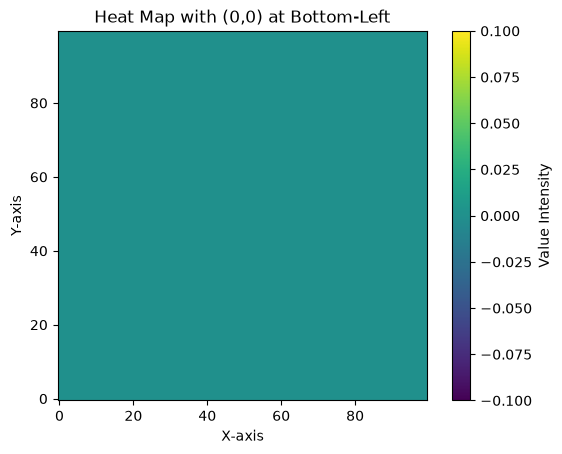

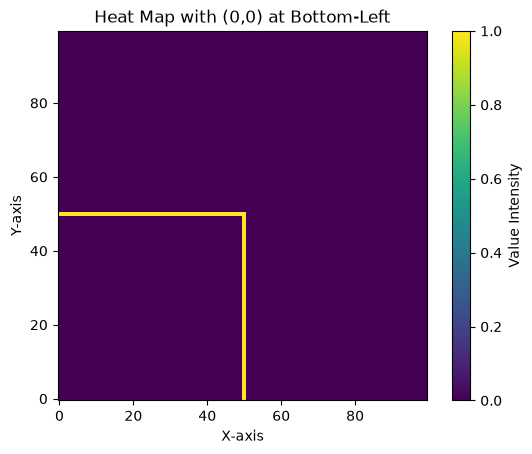

In [22]:
import numpy as np
import matplotlib.pyplot as plt

#2
a = 1
n = 100
v0 = 1
vout = 0

initial_matrix = np.zeros((n, n))
new_matrix = np.zeros((n, n))

plt.imshow(initial_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Value Intensity')
plt.title('Heat Map with (0,0) at Bottom-Left')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()

#3
for i in range(n//2):
    initial_matrix[i,n//2] = v0
    initial_matrix[n//2,i] = v0
    initial_matrix[n//2,n//2] = v0  


for i in range(n):
    initial_matrix[i,n-1] = vout
    initial_matrix[n-1,i] = vout



plt.imshow(initial_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Value Intensity')
plt.title('Heat Map with (0,0) at Bottom-Left')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()

Number of unknown points = 7200


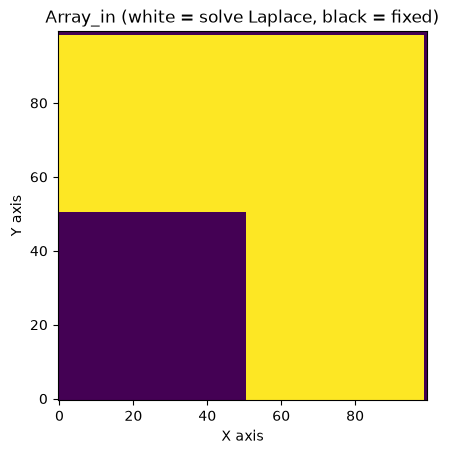

In [23]:
#4
in_ = np.ones((n, n), dtype=bool)

for k in range(n):
    in_[k, n-1] = False
    in_[n-1, k] = False

for i in range(n//2 + 1):
    for j in range(n//2 + 1):
        in_[i, j] = False

print("Number of unknown points =", np.sum(in_))

plt.imshow(in_, cmap='viridis', origin='lower')
plt.title('Array_in (white = solve Laplace, black = fixed)')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.show()

iterations = 384  last change = 9.62938395687729e-10


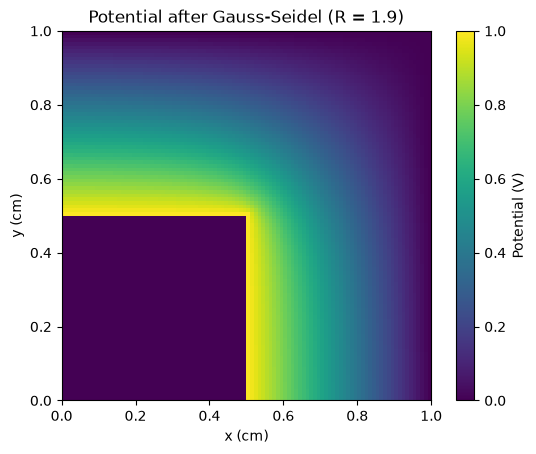

In [24]:
R = 1.9
tol = 1e-9
max_iter = 1000

for it in range(1, max_iter + 1):
    max_diff = 0.0

    for i in range(0, n-1):
        for j in range(0, n-1):
            if in_[i, j]:
                up = initial_matrix[i+1, j]
                right = initial_matrix[i, j+1]

                if i == 0:                          # symmetry
                    down = initial_matrix[1, j]
                else:
                    down = initial_matrix[i-1, j]

                if j == 0:                          # symmetry
                    left = initial_matrix[i, 1]
                else:
                    left = initial_matrix[i, j-1]

                avg = (up + down + left + right) / 4
                old = initial_matrix[i, j]
                initial_matrix[i, j] = old + R * (avg - old)

                if abs(initial_matrix[i, j] - old) > max_diff:
                    max_diff = abs(initial_matrix[i, j] - old)

    if max_diff < tol:
        break

print("iterations =", it, " last change =", max_diff)


plt.imshow(initial_matrix, cmap='viridis', origin='lower', extent=[0, 1, 0, 1])
plt.colorbar(label='Potential (V)')
plt.title('Potential after Gauss-Seidel (R = 1.9)')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.show()

In [27]:

# 7
epsilon_0 = 8.854e-12  # F/m
h = 0.01 / (n - 1)           

k = n // 2
delta_V = v0 - vout

Q_quarter = 0.0

for j in range(k + 1):
    w = 0.5 if j == 0 or j == k else 1.0

    Ex = -(initial_matrix[k + 1, j] -
           initial_matrix[k, j]) / h

    Ey = -(initial_matrix[j, k + 1] -
           initial_matrix[j, k]) / h

    Q_quarter += (Ex + Ey) * w * h

Q = epsilon_0 * 4 * Q_quarter

# Capacitance per unit length
C = Q / delta_V

print("Charge per unit length =", Q, "C/m")
print("Capacitance per unit length =", C, "F/m")


Charge per unit length = 8.979318366230778e-11 C/m
Capacitance per unit length = 8.979318366230778e-11 F/m
